# Wind Behavior in Fjords

The wind stress reduce in fjord regions could be caused by one or two of the following reasons:

1. The low resolution model could not resolve the terrains in the fjords, missing important wind passway. <- All grid values in the regions are uniformly low.

2. Land contamination. <- There are high wind values and low wind values. Low wind speed over land contaminated the weighted wind speed.

The notebook shall find out.

See https://github.com/SalishSeaCast/analysis-junqi/blob/main/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_weights/Fjords.ipynb for similar analysis for air temperature.

## NC info

In [1]:
# print variables

import xarray as xr

path_example='/ocean/jqiu/forcings/CaSR/CaSR_y2023m03d01.nc'

forcing_example=xr.open_dataset(path_example)
print(forcing_example)

<xarray.Dataset> Size: 6MB
Dimensions:       (time_counter: 24, y: 105, x: 70)
Coordinates:
  * time_counter  (time_counter) datetime64[ns] 192B 2023-03-01 ... 2023-03-0...
  * y             (y) int32 420B 0 1 2 3 4 5 6 7 ... 98 99 100 101 102 103 104
  * x             (x) int32 280B 0 1 2 3 4 5 6 7 8 ... 62 63 64 65 66 67 68 69
    nav_lat       (y, x) float32 29kB ...
    nav_lon       (y, x) float32 29kB ...
Data variables:
    solar         (time_counter, y, x) float32 706kB ...
    precip        (time_counter, y, x) float32 706kB ...
    therm_rad     (time_counter, y, x) float32 706kB ...
    tair          (time_counter, y, x) float32 706kB ...
    qair          (time_counter, y, x) float32 706kB ...
    u_wind        (time_counter, y, x) float32 706kB ...
    atmpres       (time_counter, y, x) float32 706kB ...
    v_wind        (time_counter, y, x) float32 706kB ...
    percentcloud  (time_counter, y, x) float32 706kB ...
Attributes:
    title:           Converted CaSR atmosphe

variable names for wind: 'u_wind' and 'v_wind'

## Extraction

In [3]:
# ============================================================
# Extract u_wind, v_wind and wind speed at four source points
# for Pam Rocks and Sand Heads (CaSR and HRDPS, March 2023)
# ============================================================

import xarray as xr
import pandas as pd
import numpy as np
from pathlib import Path
import glob

casr_dir = Path("/ocean/jqiu/forcings/CaSR")
hrdps_dir = Path("/results/forcing/atmospheric/continental2.5/nemo_forcing")
output_dir = Path("/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_comparison/Analysis_wind_terrain/")


casr_files = sorted(glob.glob(str(casr_dir / "CaSR_y2023m03d*.nc")))
hrdps_files = sorted(glob.glob(str(hrdps_dir / "hrdps_y2023m03d*.nc")))
print(f"CaSR files: {len(casr_files)}")
print(f"HRDPS files: {len(hrdps_files)}")
if not casr_files or not hrdps_files:
    raise FileNotFoundError("No March 2023 NetCDF files found for one or both models.")

# Four source points and interpolation weights from the original script.
source_points = {

    # --------------------------------------------------------
    # CaSR
    # --------------------------------------------------------

    "CaSR": {

        "PamRocks": [
            {
                "point": 1,
                "y": 58,
                "x": 36,
                "weight": 0.8099528243,
            },
            {
                "point": 2,
                "y": 57,
                "x": 36,
                "weight": 0.0239716401,
            },
            {
                "point": 3,
                "y": 58,
                "x": 37,
                "weight": 0.1613015984,
            },
            {
                "point": 4,
                "y": 57,
                "x": 37,
                "weight": 0.0047739371,
            },
        ],

        "SandHeads": [
            {
                "point": 1,
                "y": 54,
                "x": 34,
                "weight": 0.5675647174,
            },
            {
                "point": 2,
                "y": 55,
                "x": 34,
                "weight": 0.1233862179,
            },
            {
                "point": 3,
                "y": 54,
                "x": 35,
                "weight": 0.2538607824,
            },
            {
                "point": 4,
                "y": 55,
                "x": 35,
                "weight": 0.0551882822,
            },
        ],
    },

    # --------------------------------------------------------
    # HRDPS
    # --------------------------------------------------------

    "HRDPS": {

        "PamRocks": [
            {
                "point": 1,
                "y": 135,
                "x": 110,
                "weight": 0.6461993583,
            },
            {
                "point": 2,
                "y": 136,
                "x": 110,
                "weight": 0.2141754176,
            },
            {
                "point": 3,
                "y": 135,
                "x": 111,
                "weight": 0.1048679398,
            },
            {
                "point": 4,
                "y": 136,
                "x": 111,
                "weight": 0.0347572843,
            },
        ],

        "SandHeads": [
            {
                "point": 1,
                "y": 118,
                "x": 108,
                "weight": 0.4704031405,
            },
            {
                "point": 2,
                "y": 119,
                "x": 108,
                "weight": 0.4576466227,
            },
            {
                "point": 3,
                "y": 118,
                "x": 109,
                "weight": 0.0364696148,
            },
            {
                "point": 4,
                "y": 119,
                "x": 109,
                "weight": 0.0354806220,
            },
        ],
    },
}


def extract_model_source_points(ds, model_name, station_points):
    for name in ("u_wind", "v_wind", "nav_lat", "nav_lon"):
        if name not in ds:
            raise KeyError(f"{model_name}: missing variable {name!r}")

    u = ds["u_wind"]
    v = ds["v_wind"]
    if u.dims != v.dims:
        raise ValueError(f"{model_name}: u_wind and v_wind have different dimensions")
    if not {"time_counter", "y", "x"}.issubset(u.dims):
        raise ValueError(f"{model_name}: expected time_counter, y, x dimensions")

    print(f"{model_name}: U units = {u.attrs.get('units', 'unknown')}, "
          f"V units = {v.attrs.get('units', 'unknown')}")
    # No temperature conversion is needed. Assumes both components have
    # the same velocity units (usually m/s).
    all_dfs = []

    for station_name, points in station_points.items():
        print(f"\n{model_name} - {station_name}")
        for p in points:
            y_idx, x_idx, weight = p["y"], p["x"], p["weight"]
            u_point = u.isel(y=y_idx, x=x_idx)
            v_point = v.isel(y=y_idx, x=x_idx)

            # Compute pointwise speed using both wind components.
            point_data = xr.Dataset({
                "u_wind": u_point,
                "v_wind": v_point,
                "wind_speed": np.hypot(u_point, v_point),
            })
            df = point_data.to_dataframe().reset_index()
            df = df.drop(columns=["x", "y"], errors="ignore")

            grid_lat = float(ds["nav_lat"].isel(y=y_idx, x=x_idx).values)
            grid_lon = float(ds["nav_lon"].isel(y=y_idx, x=x_idx).values)
            grid_lon_180 = grid_lon - 360 if grid_lon > 180 else grid_lon

            print(f"point {p['point']}: (y,x)=({y_idx},{x_idx}), "
                  f"lat={grid_lat:.6f}, lon={grid_lon_180:.6f}, "
                  f"weight={weight:.10f}")

            df["model"] = model_name
            df["station"] = station_name
            df["source_point"] = p["point"]
            df["grid_y"] = y_idx
            df["grid_x"] = x_idx
            df["grid_lat"] = grid_lat
            df["grid_lon"] = grid_lon
            df["grid_lon_180"] = grid_lon_180
            df["weight"] = weight
            df["weighted_u_wind"] = df["u_wind"] * weight
            df["weighted_v_wind"] = df["v_wind"] * weight
            df["weighted_wind_speed"] = df["wind_speed"] * weight

            columns = [
                "time_counter", "model", "station", "source_point",
                "grid_y", "grid_x", "grid_lat", "grid_lon",
                "grid_lon_180", "weight", "u_wind", "v_wind",
                "wind_speed", "weighted_u_wind", "weighted_v_wind",
                "weighted_wind_speed",
            ]
            all_dfs.append(df[columns])

    return (pd.concat(all_dfs, ignore_index=True)
            .sort_values(["station", "source_point", "time_counter"])
            .reset_index(drop=True))


def save_csv(df, path):
    df.to_csv(path, index=False, date_format="%Y-%m-%d %H:%M:%S")
    print(f"Saved: {path}")


def main():
    ds_casr = xr.open_mfdataset(
        casr_files, combine="by_coords", parallel=True,
        chunks={"time_counter": 24},
    )
    ds_hrdps = xr.open_mfdataset(
        hrdps_files, combine="by_coords", parallel=True,
        chunks={"time_counter": 24},
    )
    try:
        df_casr = extract_model_source_points(
            ds_casr, "CaSR", source_points["CaSR"]
        )
        df_hrdps = extract_model_source_points(
            ds_hrdps, "HRDPS", source_points["HRDPS"]
        )
        df_all_points = pd.concat([df_casr, df_hrdps], ignore_index=True)

        # Output 1: all 16 point series (U, V, wind speed).
        save_csv(df_all_points,
                 output_dir / "CaSR_HRDPS_4sourcepoints_wind_202303.csv")

        # Output 2: interpolate U and V first, then calculate station speed.
        # min_count=4 ensures missing values do not silently produce
        # an incorrectly weighted station result.
        df_weighted = (
            df_all_points.groupby(
                ["time_counter", "model", "station"], as_index=False
            )[["weighted_u_wind", "weighted_v_wind", "weighted_wind_speed"]]
            .sum(min_count=4)
            .rename(columns={
                "weighted_u_wind": "u_weighted",
                "weighted_v_wind": "v_weighted",
                "weighted_wind_speed": "speed_weighted_scalar",
            })
        )
        df_weighted["wind_speed_weighted"] = np.hypot(
            df_weighted["u_weighted"], df_weighted["v_weighted"]
        )
        df_weighted = df_weighted.sort_values(
            ["station", "model", "time_counter"]
        ).reset_index(drop=True)
        save_csv(df_weighted,
                 output_dir / "CaSR_HRDPS_weighted_wind_202303.csv")

        # Output 3: wide format, 16 wind-speed point series.
        df_wide = (
            df_all_points.assign(
                series_name=lambda x: x["model"] + "_" + x["station"]
                + "_P" + x["source_point"].astype(str)
            )
            .pivot(index="time_counter", columns="series_name",
                   values="wind_speed")
            .sort_index()
            .reset_index()
        )
        df_wide.columns.name = None
        save_csv(df_wide,
                 output_dir / "CaSR_HRDPS_wind_speed.csv")
    finally:
        ds_casr.close()
        ds_hrdps.close()
    print("All done.")


if __name__ == "__main__":
    main()


CaSR files: 31
HRDPS files: 31
CaSR: U units = m/s, V units = m/s

CaSR - PamRocks
point 1: (y,x)=(58,36), lat=49.483242, lon=-123.323914, weight=0.8099528243
point 2: (y,x)=(57,36), lat=49.402325, lon=-123.263321, weight=0.0239716401
point 3: (y,x)=(58,37), lat=49.522491, lon=-123.199615, weight=0.1613015984
point 4: (y,x)=(57,37), lat=49.441509, lon=-123.139206, weight=0.0047739371

CaSR - SandHeads
point 1: (y,x)=(54,34), lat=49.081009, lon=-123.329330, weight=0.5675647174
point 2: (y,x)=(55,34), lat=49.161884, lon=-123.389679, weight=0.1233862179
point 3: (y,x)=(54,35), lat=49.120274, lon=-123.206131, weight=0.2538607824
point 4: (y,x)=(55,35), lat=49.201210, lon=-123.266296, weight=0.0551882822
HRDPS: U units = m s-1, V units = m s-1

HRDPS - PamRocks
point 1: (y,x)=(135,110), lat=49.481496, lon=-123.305272, weight=0.6461993583
point 2: (y,x)=(136,110), lat=49.503828, lon=-123.309472, weight=0.2141754176
point 3: (y,x)=(135,111), lat=49.484212, lon=-123.270976, weight=0.1048679398

## Grid Point Location

Recall that:
```
#################### CaSR ####################

Station coordinate: lat=49.487434, lon=-123.30153
================================================================================
Pam Rocks
NEMO target index: y=502, x=341
Atmospheric source grid: nlat=105, nlon=70
================================================================================
source 1: src=  4097, (ilat, ilon)=(  58,   36), lat= 49.483242, lon= 236.676086, weight=0.8099528243
source 2: src=  4027, (ilat, ilon)=(  57,   36), lat= 49.402325, lon= 236.736679, weight=0.0239716401
source 3: src=  4098, (ilat, ilon)=(  58,   37), lat= 49.522491, lon= 236.800385, weight=0.1613015984
source 4: src=  4028, (ilat, ilon)=(  57,   37), lat= 49.441509, lon= 236.860794, weight=0.0047739371
--------------------------------------------------------------------------------
sum(weights) = 1.000000000000

Station coordinate: lat=49.107586, lon=-123.30203
================================================================================
Sand Heads
NEMO target index: y=428, x=293
Atmospheric source grid: nlat=105, nlon=70
================================================================================
source 1: src=  3815, (ilat, ilon)=(  54,   34), lat= 49.081009, lon= 236.670670, weight=0.5675647174
source 2: src=  3885, (ilat, ilon)=(  55,   34), lat= 49.161884, lon= 236.610321, weight=0.1233862179
source 3: src=  3816, (ilat, ilon)=(  54,   35), lat= 49.120274, lon= 236.793869, weight=0.2538607824
source 4: src=  3886, (ilat, ilon)=(  55,   35), lat= 49.201210, lon= 236.733704, weight=0.0551882822
--------------------------------------------------------------------------------
sum(weights) = 1.000000000000



#################### HRDPS ####################

Station coordinate: lat=49.487434, lon=-123.30153
================================================================================
Pam Rocks
NEMO target index: y=502, x=341
Atmospheric source grid: nlat=230, nlon=190
================================================================================
source 1: src= 25761, (ilat, ilon)=( 135,  110), lat= 49.481496, lon= 236.694728, weight=0.6461993583
source 2: src= 25951, (ilat, ilon)=( 136,  110), lat= 49.503828, lon= 236.690528, weight=0.2141754176
source 3: src= 25762, (ilat, ilon)=( 135,  111), lat= 49.484212, lon= 236.729024, weight=0.1048679398
source 4: src= 25952, (ilat, ilon)=( 136,  111), lat= 49.506548, lon= 236.724832, weight=0.0347572843
--------------------------------------------------------------------------------
sum(weights) = 1.000000000000

Station coordinate: lat=49.107586, lon=-123.30203
================================================================================
Sand Heads
NEMO target index: y=428, x=293
Atmospheric source grid: nlat=230, nlon=190
================================================================================
source 1: src= 22529, (ilat, ilon)=( 118,  108), lat= 49.096376, lon= 236.697576, weight=0.4704031405
source 2: src= 22719, (ilat, ilon)=( 119,  108), lat= 49.118712, lon= 236.693408, weight=0.4576466227
source 3: src= 22530, (ilat, ilon)=( 118,  109), lat= 49.099092, lon= 236.731584, weight=0.0364696148
source 4: src= 22720, (ilat, ilon)=( 119,  109), lat= 49.121428, lon= 236.727432, weight=0.0354806220
--------------------------------------------------------------------------------
sum(weights) = 1.000000000000
```

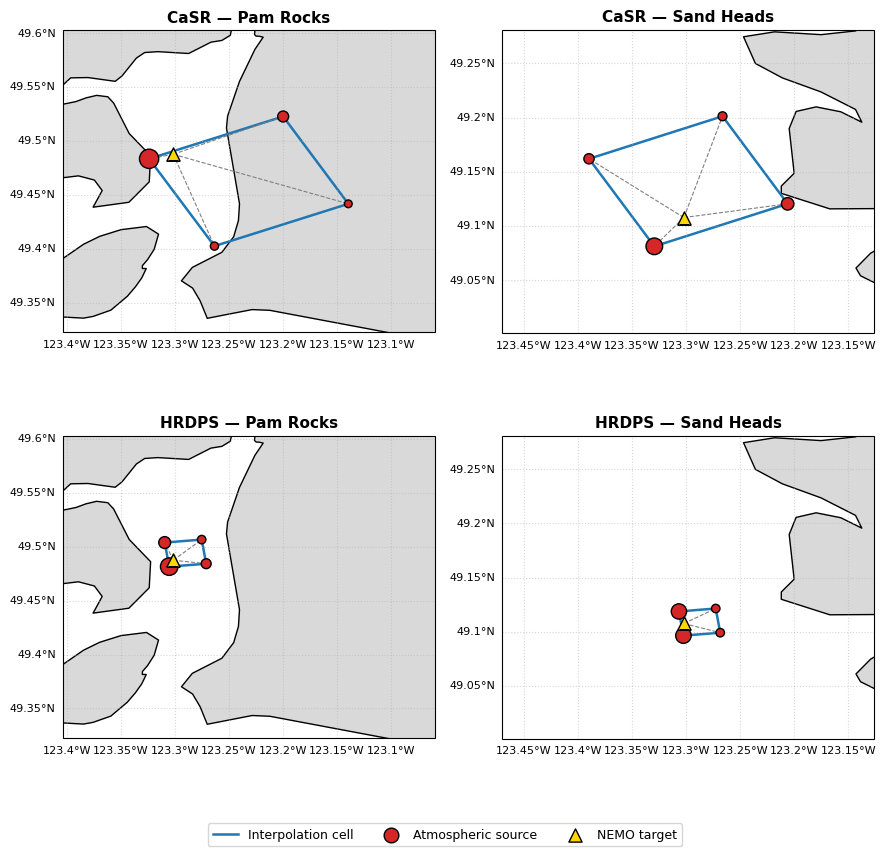

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Station coordinates
stations = {
    "Pam Rocks": (-123.30153, 49.487434),
    "Sand Heads": (-123.30203, 49.107586),
}

# Atmospheric source points: (longitude, latitude, weight)
data = {
    "CaSR": {
        "Pam Rocks": [
            (236.676086, 49.483242, 0.8099528243),
            (236.736679, 49.402325, 0.0239716401),
            (236.800385, 49.522491, 0.1613015984),
            (236.860794, 49.441509, 0.0047739371),
        ],
        "Sand Heads": [
            (236.670670, 49.081009, 0.5675647174),
            (236.610321, 49.161884, 0.1233862179),
            (236.793869, 49.120274, 0.2538607824),
            (236.733704, 49.201210, 0.0551882822),
        ],
    },
    "HRDPS": {
        "Pam Rocks": [
            (236.694728, 49.481496, 0.6461993583),
            (236.690528, 49.503828, 0.2141754176),
            (236.729024, 49.484212, 0.1048679398),
            (236.724832, 49.506548, 0.0347572843),
        ],
        "Sand Heads": [
            (236.697576, 49.096376, 0.4704031405),
            (236.693408, 49.118712, 0.4576466227),
            (236.731584, 49.099092, 0.0364696148),
            (236.727432, 49.121428, 0.0354806220),
        ],
    },
}

# Convert longitude to -180 ~ 180
for model in data:
    for station in data[model]:
        data[model][station] = np.array(data[model][station])
        data[model][station][:, 0] -= 360

# Common extent for each station
extents = {}

for station, (target_lon, target_lat) in stations.items():
    pts = np.vstack([data[m][station] for m in data])

    lon = np.append(pts[:, 0], target_lon)
    lat = np.append(pts[:, 1], target_lat)

    extents[station] = [
        lon.min() - 0.08,
        lon.max() + 0.08,
        lat.min() - 0.08,
        lat.max() + 0.08,
    ]


# Plot one subplot
def plot_map(ax, model, station):
    pts = data[model][station]
    lon, lat, weights = pts.T
    target_lon, target_lat = stations[station]

    ax.add_feature(cfeature.LAND, facecolor="0.85")
    ax.coastlines(linewidth=1)

    # Connect the 4 atmospheric points into a polygon
    angle = np.arctan2(lat - lat.mean(), lon - lon.mean())
    order = np.argsort(angle)
    polygon = np.r_[order, order[0]]

    ax.plot(
        lon[polygon], lat[polygon],
        "-", color="tab:blue", linewidth=1.8,
        transform=ccrs.PlateCarree(),
        label="Interpolation cell"
    )

    # Dashed lines from NEMO target to source points
    for x, y in zip(lon, lat):
        ax.plot(
            [target_lon, x], [target_lat, y],
            "--", color="0.5", linewidth=0.8,
            transform=ccrs.PlateCarree()
        )

    # 4 atmospheric source points
    ax.scatter(
        lon, lat,
        s=30 + 200 * weights,
        c="tab:red", edgecolors="black",
        zorder=5, transform=ccrs.PlateCarree(),
        label="Atmospheric source"
    )

    # NEMO target
    ax.scatter(
        target_lon, target_lat,
        s=90, marker="^", color="gold",
        edgecolors="black", zorder=6,
        transform=ccrs.PlateCarree(),
        label="NEMO target"
    )

    ax.set_extent(extents[station], crs=ccrs.PlateCarree())

    gl = ax.gridlines(draw_labels=True, linestyle=":", alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}

    ax.set_title(f"{model} — {station}", fontsize=11, fontweight="bold")


# 2 x 2 figure
fig, axes = plt.subplots(
    2, 2, figsize=(9, 9),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for i, model in enumerate(["CaSR", "HRDPS"]):
    for j, station in enumerate(["Pam Rocks", "Sand Heads"]):
        plot_map(axes[i, j], model, station)

# Common legend
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=3, fontsize=9,
    bbox_to_anchor=(0.5, 0.01)
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


## Wind Speed Visualization

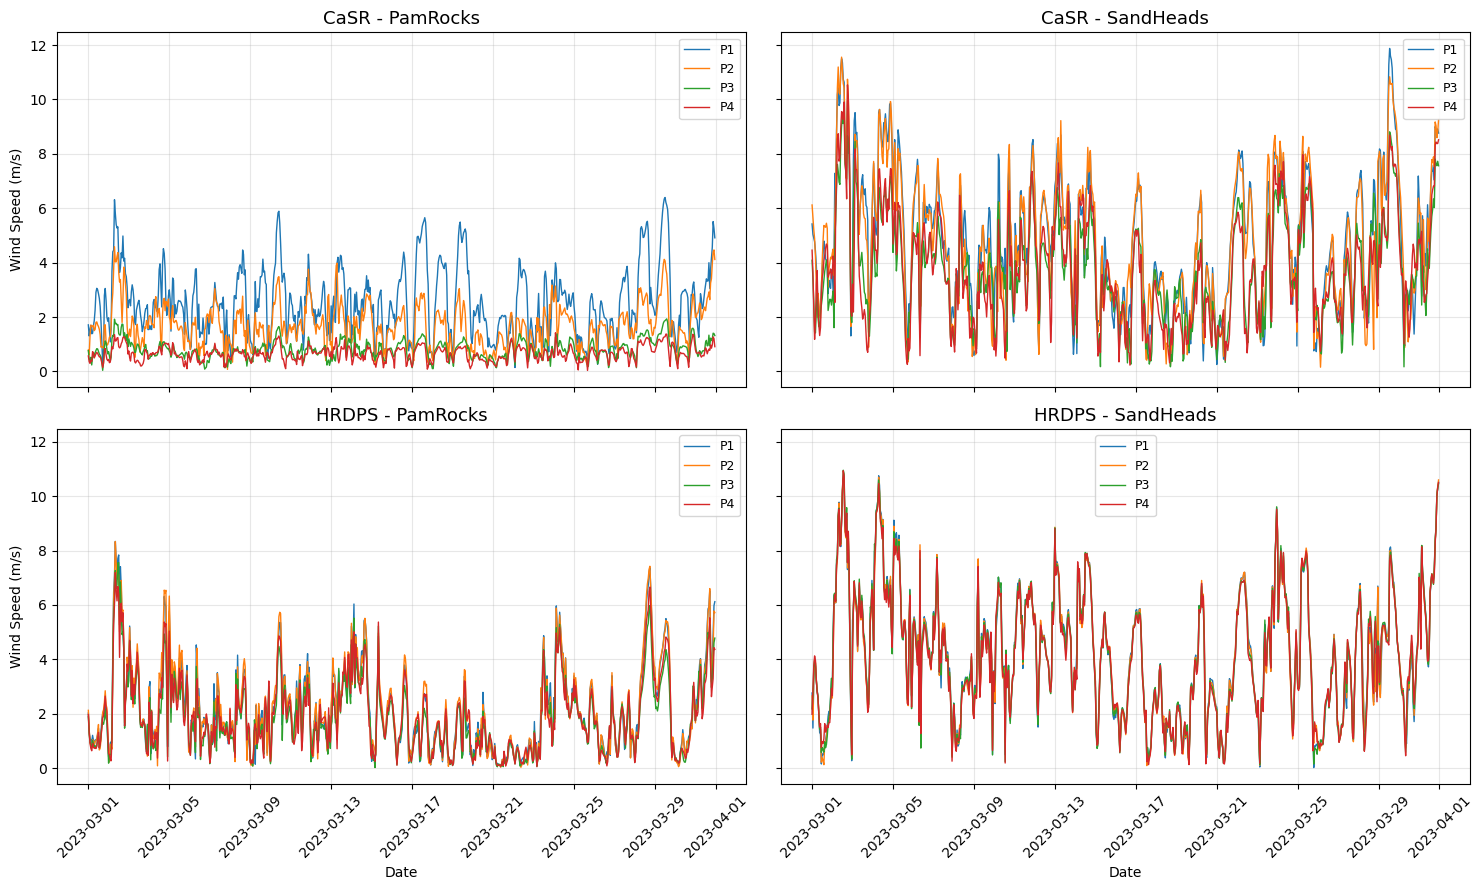

In [7]:



import pandas as pd
import matplotlib.pyplot as plt

# paths

path_points = (
    "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/"
    "Analysis_forcing_comparison/Analysis_wind_terrain/"
    "CaSR_HRDPS_wind_speed.csv"
)

# ============================================================
# 2. Read data
# ============================================================

df = pd.read_csv(path_points)

df["time_counter"] = pd.to_datetime(df["time_counter"])

# visualize

models = [
    "CaSR",
    "HRDPS",
]

stations = [
    "PamRocks",
    "SandHeads",
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(15, 9),
    sharex=True,
    sharey=True,
)

for row, model in enumerate(models):

    for col, station in enumerate(stations):

        ax = axes[row, col]

        # --------------------------------------------
        # Plot four source points
        # --------------------------------------------

        for point_number in [1, 2, 3, 4]:

            column_name = (
                f"{model}_{station}_P{point_number}"
            )

            ax.plot(
                df["time_counter"],
                df[column_name],
                linewidth=1.0,
                label=f"P{point_number}",
            )

        ax.set_title(
            f"{model} - {station}",
            fontsize=13,
        )

        ax.grid(
            True,
            alpha=0.3,
        )

        ax.legend(
            fontsize=9,
        )

        ax.tick_params(
            axis="x",
            rotation=45,
        )

# Labels


axes[0, 0].set_ylabel("Wind Speed (m/s)")
axes[1, 0].set_ylabel("Wind Speed (m/s)")

axes[1, 0].set_xlabel("Date")
axes[1, 1].set_xlabel("Date")

plt.tight_layout()

plt.show()


It seems that at Pam Rocks, land contamination is the main source of wind-stress reduce. We could see higher and lower wind speeds, indicating that CaSR model could resolve that there is a fjord.

## Adjust fig (just for demonstration)

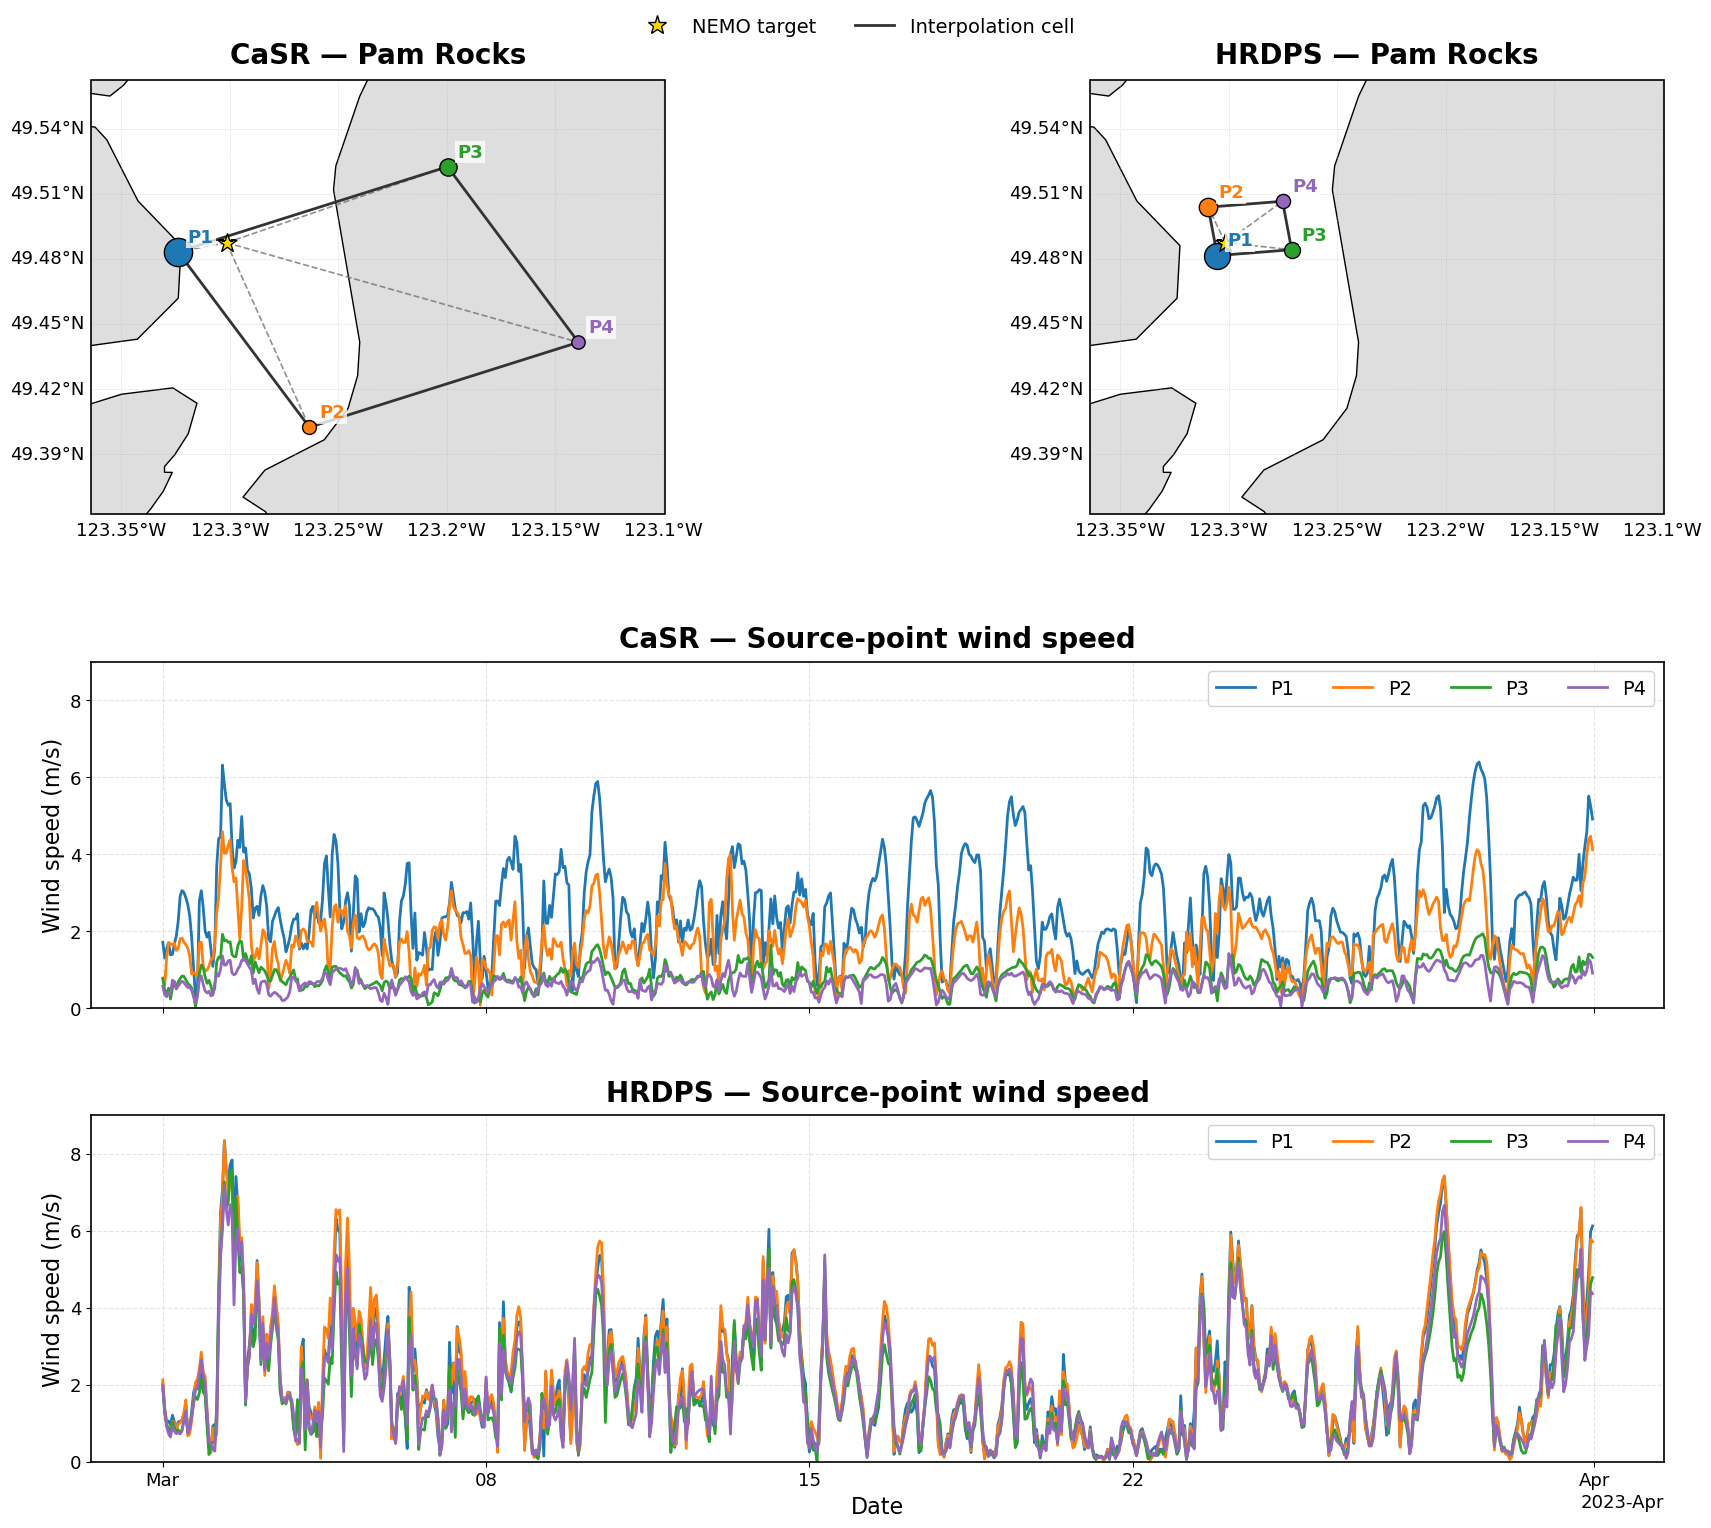

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

# ============================================================
# 1. Configuration
# ============================================================

CSV_PATH = (
    "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/"
    "Analysis_forcing_comparison/Analysis_wind_terrain/"
    "CaSR_HRDPS_wind_speed.csv"
)

STATION_NAME = "Pam Rocks"
STATION_LON = -123.30153
STATION_LAT = 49.487434

MODELS = ["CaSR", "HRDPS"]

# Font sizes for PPT
TITLE_SIZE = 20
LABEL_SIZE = 16
TICK_SIZE = 13
LEGEND_SIZE = 14

# Colors for P1-P4, consistent across maps and time series
POINT_COLORS = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:purple",
]

plt.rcParams.update({
    "font.size": TICK_SIZE,
    "axes.titlesize": TITLE_SIZE,
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
    "legend.fontsize": LEGEND_SIZE,
    "axes.linewidth": 1.2,
})

# ============================================================
# 2. Atmospheric source points (lon, lat, weight)
# ============================================================

source_data = {
    "CaSR": np.array([
        (236.676086, 49.483242, 0.8099528243),
        (236.736679, 49.402325, 0.0239716401),
        (236.800385, 49.522491, 0.1613015984),
        (236.860794, 49.441509, 0.0047739371),
    ], dtype=float),

    "HRDPS": np.array([
        (236.694728, 49.481496, 0.6461993583),
        (236.690528, 49.503828, 0.2141754176),
        (236.729024, 49.484212, 0.1048679398),
        (236.724832, 49.506548, 0.0347572843),
    ], dtype=float),
}

# Convert 0-360 longitude to -180-180
for model in MODELS:
    source_data[model][:, 0] -= 360

# Common geographical extent
all_points = np.vstack([source_data[m] for m in MODELS])

all_lon = np.append(all_points[:, 0], STATION_LON)
all_lat = np.append(all_points[:, 1], STATION_LAT)

MAP_EXTENT = [
    all_lon.min() - 0.04,
    all_lon.max() + 0.04,
    all_lat.min() - 0.04,
    all_lat.max() + 0.04,
]

# ============================================================
# 3. Read time series data
# ============================================================

df = pd.read_csv(CSV_PATH)
df["time_counter"] = pd.to_datetime(df["time_counter"])
df = df.sort_values("time_counter")

# Check required columns
for model in MODELS:
    for p in range(1, 5):
        col = f"{model}_PamRocks_P{p}"
        if col not in df.columns:
            raise ValueError(f"Missing CSV column: {col}")

# ============================================================
# 4. Map plotting function
# ============================================================

def plot_map(ax, model):

    pts = source_data[model]
    lon, lat, weights = pts.T

    transform = ccrs.PlateCarree()

    ax.add_feature(
        cfeature.LAND,
        facecolor="0.87",
        edgecolor="none",
        zorder=0,
    )

    ax.coastlines(
        resolution="10m",
        linewidth=1.0,
        zorder=1,
    )

    # Interpolation cell
    angle = np.arctan2(
        lat - lat.mean(),
        (lon - lon.mean()) * np.cos(np.deg2rad(lat.mean()))
    )

    order = np.argsort(angle)
    polygon = np.r_[order, order[0]]

    ax.plot(
        lon[polygon],
        lat[polygon],
        "-",
        color="0.2",
        linewidth=2.0,
        transform=transform,
        zorder=3,
    )

    # Connections to NEMO target
    for x, y in zip(lon, lat):
        ax.plot(
            [STATION_LON, x],
            [STATION_LAT, y],
            "--",
            color="0.45",
            linewidth=1.2,
            alpha=0.8,
            transform=transform,
            zorder=2,
        )

    # Source points
    for i, (x, y, w) in enumerate(pts):

        ax.scatter(
            x, y,
            s=90 + 400 * w,
            color=POINT_COLORS[i],
            edgecolor="black",
            linewidth=1.0,
            transform=transform,
            zorder=5,
        )

        # Point labels
        ax.annotate(
            f"P{i+1}",
            xy=(x, y),
            xycoords=transform._as_mpl_transform(ax),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=13,
            fontweight="bold",
            color=POINT_COLORS[i],
            zorder=7,
            bbox=dict(
                facecolor="white",
                alpha=0.8,
                edgecolor="none",
                pad=1.5,
            ),
        )

    # NEMO target
    ax.scatter(
        STATION_LON,
        STATION_LAT,
        s=200,
        marker="*",
        color="gold",
        edgecolor="black",
        linewidth=1.0,
        transform=transform,
        zorder=6,
    )

    ax.set_extent(
        MAP_EXTENT,
        crs=transform,
    )

    # Grid lines
    gl = ax.gridlines(
        crs=transform,
        draw_labels=True,
        linewidth=0.7,
        linestyle=":",
        alpha=0.5,
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {"size": TICK_SIZE}
    gl.ylabel_style = {"size": TICK_SIZE}

    ax.set_title(
        f"{model} — {STATION_NAME}",
        fontsize=TITLE_SIZE,
        fontweight="bold",
        pad=12,
    )


# ============================================================
# 5. Time series plotting function
# ============================================================

def plot_timeseries(ax, model):

    for i in range(4):

        point = i + 1
        column_name = f"{model}_PamRocks_P{point}"

        ax.plot(
            df["time_counter"],
            df[column_name],
            color=POINT_COLORS[i],
            linewidth=2.0,
            label=f"P{point}",
        )

    ax.set_title(
        f"{model} — Source-point wind speed",
        fontsize=TITLE_SIZE,
        fontweight="bold",
        pad=10,
    )

    ax.set_ylabel(
        "Wind speed (m/s)",
        fontsize=LABEL_SIZE,
    )

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.8,
        alpha=0.35,
    )

    ax.tick_params(
        axis="both",
        labelsize=TICK_SIZE,
    )

    ax.legend(
        loc="upper right",
        ncol=4,
        fontsize=LEGEND_SIZE,
        framealpha=0.9,
    )

    # Automatic readable date ticks
    locator = mdates.AutoDateLocator(
        minticks=4,
        maxticks=8,
    )

    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )


# ============================================================
# 6. Combined figure
# ============================================================

fig = plt.figure(figsize=(17, 15), constrained_layout=True)

# 3 rows:
# row 1: two maps
# row 2: CaSR time series
# row 3: HRDPS time series

gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    height_ratios=[1.55, 1.0, 1.0],
    hspace=0.12,
    wspace=0.12,
)

# Maps
ax_map_casr = fig.add_subplot(
    gs[0, 0],
    projection=ccrs.PlateCarree(),
)

ax_map_hrdps = fig.add_subplot(
    gs[0, 1],
    projection=ccrs.PlateCarree(),
)

plot_map(ax_map_casr, "CaSR")
plot_map(ax_map_hrdps, "HRDPS")

# Time series (span both columns)
ax_ts_casr = fig.add_subplot(gs[1, :])

ax_ts_hrdps = fig.add_subplot(
    gs[2, :],
    sharex=ax_ts_casr,
    sharey=ax_ts_casr,
)

plot_timeseries(ax_ts_casr, "CaSR")
plot_timeseries(ax_ts_hrdps, "HRDPS")

# Same y limits
all_series = [
    df[f"{model}_PamRocks_P{p}"].to_numpy()
    for model in MODELS
    for p in range(1, 5)
]

all_values = np.concatenate(all_series)
finite_values = all_values[np.isfinite(all_values)]

if finite_values.size:
    ymin = min(0.0, finite_values.min())
    ymax = finite_values.max()
    margin = max(0.5, (ymax - ymin) * 0.08)

    ax_ts_casr.set_ylim(ymin, ymax + margin)

# Show date labels only at bottom
ax_ts_casr.tick_params(
    axis="x",
    labelbottom=False,
)

ax_ts_hrdps.set_xlabel(
    "Date",
    fontsize=LABEL_SIZE,
)

# Common map legend
map_handles = [
    Line2D(
        [0], [0],
        marker="*",
        color="none",
        markerfacecolor="gold",
        markeredgecolor="black",
        markersize=14,
        label="NEMO target",
    ),
    Line2D(
        [0], [0],
        color="0.2",
        linewidth=2,
        label="Interpolation cell",
    ),
]

fig.legend(
    handles=map_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.015),
    ncol=2,
    fontsize=LEGEND_SIZE,
    frameon=False,
)

plt.show()
